In [293]:
import os 
import pandas as pd 
import numpy as np 
from datasets.Harmonized_Datasets import harmonize
import matplotlib.pyplot as plt
import seaborn as sns

In [294]:
mf_ad = harmonize()["Moffitt"]
ex_vivo_dir = "../../data/Moffitt/ExVivo_Drug_Response/ABT-199/" 


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


DeCampos Annotated data found!
Number of Harmonized Genes: 18672


In [295]:
mf_ad.obs

,ABT-199,ExVivo_SampleID,patientID,t11_14,WES_SampleID,Disease_Status,Calculated_AUC,Calculated_VUC,Calculated_VUC_Log_Conc
RNA_SampleID,,,,,,,,,
SL414065,68.289579,Pt429,GDH03df143c,NaN,SL409637,ERMM,68.344670,73.757481,68.956557
SL316611,96.238950,Pt227,GDH08065638,0.0,NaN,LRMM,100.567017,97.296106,100.189895
SL399348,65.236880,Pt382,GDH087884bf,0.0,SL393230,ERMM,70.912442,65.555466,70.094156
SL242336,81.704820,Pt166,GDH0bd4be69,1.0,SL241599,LRMM,85.652016,82.164171,84.519450
SL414057,86.576130,Pt419,GDH10e17fff,NaN,SL409628,ERMM,91.876456,86.337454,90.837244
...,...,...,...,...,...,...,...,...,...
SL432596,100.000000,Pt516,GDHea79fae2,NaN,SL434811,ERMM,100.779010,100.488545,100.612910
SL425882,99.259752,Pt478,GDHefa46356,NaN,SL426500,LRMM,98.816654,99.091609,97.717609
SL240795,88.815766,Pt143,GDHf5b6b0bc,0.0,SL241566,ERMM,93.071237,88.340142,92.772272


<Axes: xlabel='ABT-199', ylabel='Calculated_AUC'>

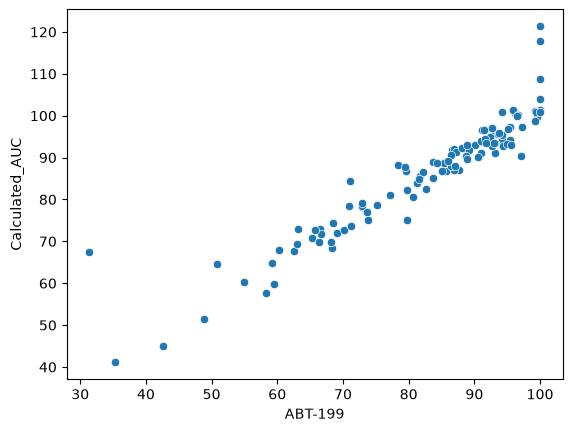

In [296]:
sns.scatterplot(mf_ad.obs, x='ABT-199', y='Calculated_AUC')

<Axes: xlabel='ABT-199', ylabel='Calculated_VUC'>

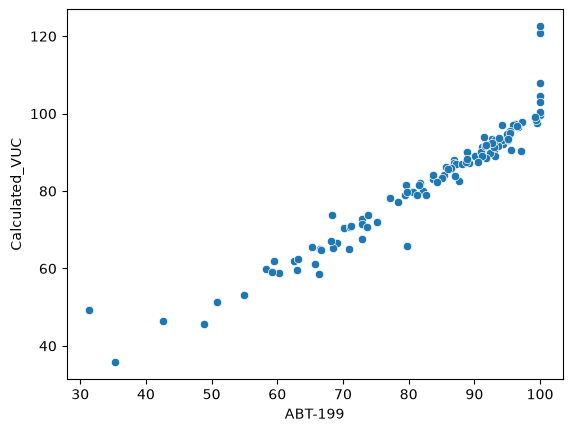

In [297]:
sns.scatterplot(mf_ad.obs, x='ABT-199', y='Calculated_VUC')

<Axes: xlabel='ABT-199', ylabel='Calculated_VUC_Log_Conc'>

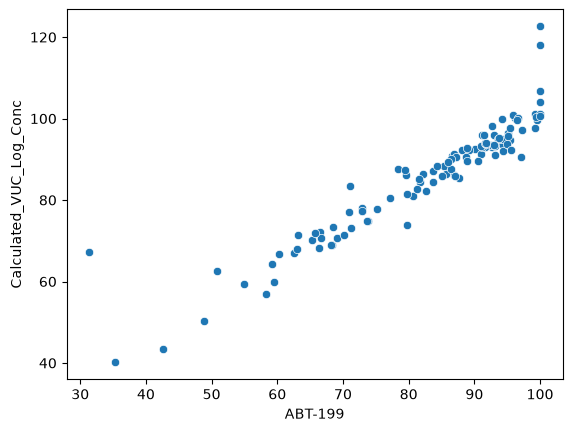

In [298]:
sns.scatterplot(mf_ad.obs, x='ABT-199', y='Calculated_VUC_Log_Conc')

In [216]:
file_names = []
for file_name in os.listdir(ex_vivo_dir):
    file_names.append(file_name)

In [217]:
df = pd.read_csv(ex_vivo_dir + 'Pt429.csv')
df

,Time(h),10.0uM,10.0uM.1,3.3333333uM,3.3333333uM.1,1.1111112uM,1.1111112uM.1,0.37037036uM,0.37037036uM.1,0.12345679uM,0.12345679uM.1,Unnamed: 11
0,0.0,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,NaN
1,0.5,99.922460,103.220430,98.907000,97.327050,102.262886,94.821655,100.756720,104.830605,100.690940,103.833840,NaN
2,1.0,105.771560,104.322525,93.176765,94.291160,97.525350,93.851380,101.269210,87.225550,98.170170,101.805610,NaN
3,1.5,94.633420,103.320435,97.640114,103.931690,97.903650,95.200030,97.545280,88.431175,99.982050,100.347960,NaN
4,2.0,98.193880,101.751520,96.016624,97.990740,94.664635,99.206710,107.211810,103.613580,97.515060,98.968840,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
193,96.5,54.954334,98.299420,45.786896,51.797585,49.074955,42.238620,40.695164,45.448624,56.354890,63.907078,NaN
194,97.0,57.805653,96.705570,41.438686,49.261333,44.490320,37.585130,43.964657,45.678310,54.248436,49.398130,NaN
195,97.5,55.646800,99.444910,41.923435,51.474426,48.536846,39.152782,39.339573,59.636013,53.270800,65.133194,NaN
196,98.0,54.628174,103.238850,42.142387,55.948680,45.590363,40.964150,35.561443,63.847366,52.236816,68.340580,NaN


In [218]:
dfs = {}
not_found_files = []
for idx in mf_ad.obs['ExVivo_SampleID']:
    file_name = ex_vivo_dir + idx + ".csv"
    #print(file_name)
    #if file_name in file_names:
    try: 
        df = pd.read_csv(file_name).set_index('Time(h)')
        df = df[[col for col in df.columns if col != 'Unnamed: 11']]
        dfs[idx] = df
    except FileNotFoundError as E:
        not_found_files.append(idx)

In [219]:
f'number of missing files: {len(mf_ad.obs) - len(dfs.keys())}'

'number of missing files: 6'

In [220]:
not_found_files

['Pt453', 'Pt486', 'Pt459', 'Pt484', 'Pt462', 'Pt460']

In [221]:
files_for_missing_ids = []
for file_name in file_names:
    for not_found_file in not_found_files:
        if file_name.startswith(not_found_file):
            files_for_missing_ids.append(file_name)

In [222]:
sorted(files_for_missing_ids) # These patients have multiple replicates, it could be because these samples were taken at different stages of their disease
# I'll use the first replicate for each using the _1 suffix

['Pt453_1.csv',
 'Pt453_2.csv',
 'Pt459_1.csv',
 'Pt459_2.csv',
 'Pt460_1.csv',
 'Pt460_2.csv',
 'Pt462_1.csv',
 'Pt462_2.csv',
 'Pt484_1.csv',
 'Pt484_2.csv',
 'Pt486_1.csv',
 'Pt486_2.csv']

In [223]:
for not_found_file in not_found_files:
    df = pd.read_csv(ex_vivo_dir + not_found_file + "_1.csv").set_index('Time(h)').drop('Unnamed: 11', axis=1)
    df = df[[col for col in df.columns if col != 'Unnamed: 11']]
    dfs[not_found_file] = df

In [224]:
f'number of missing files: {len(mf_ad.obs) - len(dfs.keys())}'

'number of missing files: 0'

In [225]:
# time goes up by 0.5 hours each time - the 96 hour mark seems to be index = 193
for key in dfs:
    dfs[key] = dfs[key].iloc[:193]

In [226]:
dfs['Pt429']

,10.0uM,10.0uM.1,3.3333333uM,3.3333333uM.1,1.1111112uM,1.1111112uM.1,0.37037036uM,0.37037036uM.1,0.12345679uM,0.12345679uM.1
Time(h),,,,,,,,,,
0.0,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
0.5,99.922460,103.220430,98.907000,97.327050,102.262886,94.821655,100.756720,104.830605,100.690940,103.833840
1.0,105.771560,104.322525,93.176765,94.291160,97.525350,93.851380,101.269210,87.225550,98.170170,101.805610
1.5,94.633420,103.320435,97.640114,103.931690,97.903650,95.200030,97.545280,88.431175,99.982050,100.347960
2.0,98.193880,101.751520,96.016624,97.990740,94.664635,99.206710,107.211810,103.613580,97.515060,98.968840
...,...,...,...,...,...,...,...,...,...,...
94.0,53.635210,94.505844,44.042423,55.408280,47.211678,43.348812,41.950360,59.234093,51.831540,66.290120
94.5,56.413937,95.396120,44.199623,54.027676,45.194010,43.996910,41.987827,49.515570,54.683890,60.691850
95.0,61.830734,94.549390,42.295128,56.308235,47.695675,41.720104,40.564550,53.465910,59.587840,64.394455


In [227]:
# I need to find the highest dose and also deal with replicates
# Only include patients that received 10.0 micrograms
# When I add the AUC column I will have to make patients without this highest does null
highest_doses = {}
num_replicates = {}
patients_without_highest_dose = []
for key in dfs:
    df = dfs[key]
    cols = [float(col[:4]) for col in df.columns]
    #cols
    highest_dose = max(cols)
    if highest_dose == 10.0:
        highest_doses[key] = highest_dose
        num_replicates[key] = cols.count(10.0)
    else:
        patients_without_highest_dose.append(key)


In [228]:
patients_without_highest_dose

['Pt235']

In [229]:
highest_doses = pd.Series(highest_doses)
highest_doses.unique()

array([10.])

In [230]:
# how many replicates does each patient have at the highest dose
# it seems like only one patient has one replicate, all other have two
num_replicates = pd.Series(num_replicates)
num_replicates.nunique() 


2

In [284]:
# Find the average of columns that startwith ten
highest_dose_dfs = {}
all_doses_dfs = {} # for all concentrations 
vucs = {}
vucs_log_conc = {}
for key in dfs:
    df = dfs[key]
    replicate_columns = [col for col in df.columns if col.startswith("10.0")]
    df_subset = df[replicate_columns]
    average_viability = df_subset.mean(axis=1)
    highest_dose_dfs[key] = average_viability


    dose_means = df.T.groupby(df.columns.str[:3]).mean().T
    all_doses_dfs[key] = dose_means.mean(axis=1) 
    
    # get vuc 
    doses = sorted(df.T.groupby(df.columns.str[:4]).mean().T.columns.astype(float))
    print(doses)

    time_auc = np.trapezoid(
    dose_means.to_numpy(),
    x=np.array(df.index.astype(float)),
    axis=0
    )

    surface_auc = np.trapezoid(
        time_auc,
        x=doses
    )

    surface_metric = surface_auc / (96 * (max(doses) - min(doses)))
    vucs[key] = surface_metric

    # get vuc with log dosage

    time_points = np.array(df.index.astype(float))

    vuc_log_conc = np.trapezoid(
        time_auc,
        x=np.log(doses)
    ) / (
        (time_points[-1] - time_points[0])
        * (np.log(doses[-1]) - np.log(doses[0]))
    )
    vucs_log_conc[key] = vuc_log_conc
 

[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0.37, 1.11, 3.33, 10.0]
[0.12, 0

In [285]:
vucs_df = pd.Series(vucs)
vucs_log_dose_df = pd.Series(vucs_log_conc)


In [279]:
vucs_df

Pt429    22.056373
Pt227    34.255922
Pt382    22.021102
Pt166    25.225327
Pt419    28.433306
           ...    
Pt486    30.467616
Pt459    28.383693
Pt484    30.688323
Pt462    32.027594
Pt460    28.396388
Length: 111, dtype: float64

In [286]:
vucs_log_dose_df

Pt429     68.956557
Pt227    100.189895
Pt382     70.094156
Pt166     84.519450
Pt419     90.837244
            ...    
Pt486     91.173278
Pt459     92.402114
Pt484     93.545790
Pt462     99.538341
Pt460     89.561364
Length: 111, dtype: float64

In [232]:
# Now I have the viability at highest dose from 0 - 96 hours (avg viability across replicates)
# I can use the trapezoidal use to calculate AUC for each patient 
# For patients whose ID is not in the highest_dose_dfs I will give them an AUC of nan
highest_dose_dfs


{'Pt429': Time(h)
 0.0     100.000000
 0.5     101.571445
 1.0     105.047043
 1.5      98.976928
 2.0      99.972700
            ...    
 94.0     74.070527
 94.5     75.905029
 95.0     78.190062
 95.5     82.267045
 96.0     77.564295
 Length: 193, dtype: float64,
 'Pt227': Time(h)
 0.0     100.000000
 0.5      97.240763
 1.0      99.324971
 1.5     102.128778
 2.0      99.169660
            ...    
 94.0     83.230280
 94.5     82.409312
 95.0     82.275180
 95.5     82.152290
 96.0     81.575970
 Length: 193, dtype: float64,
 'Pt382': Time(h)
 0.0     100.000000
 0.5     101.141075
 1.0     100.061605
 1.5      93.995467
 2.0      96.193452
            ...    
 94.0     41.374743
 94.5     36.809658
 95.0     38.713032
 95.5     40.137104
 96.0     38.486722
 Length: 193, dtype: float64,
 'Pt166': Time(h)
 0.0     100.000000
 0.5      98.639752
 1.0      98.897560
 1.5     100.173630
 2.0     100.615735
            ...    
 94.0     66.668755
 94.5     65.938597
 95.0     65.06183

In [233]:
observations_df = pd.DataFrame(mf_ad.obs.copy())

In [234]:
observations_df['RNA_SampleID'] = observations_df.index
observations_df = observations_df.set_index('ExVivo_SampleID')


In [235]:
obs_subset_df = observations_df.loc[list(highest_dose_dfs.keys())]

In [236]:
obs_subset_df

,ABT-199,patientID,t11_14,WES_SampleID,Disease_Status,RNA_SampleID
ExVivo_SampleID,,,,,,
Pt429,68.289579,GDH03df143c,NaN,SL409637,ERMM,SL414065
Pt227,96.238950,GDH08065638,0.0,NaN,LRMM,SL316611
Pt382,65.236880,GDH087884bf,0.0,SL393230,ERMM,SL399348
Pt166,81.704820,GDH0bd4be69,1.0,SL241599,LRMM,SL242336
Pt419,86.576130,GDH10e17fff,NaN,SL409628,ERMM,SL414057
...,...,...,...,...,...,...
Pt486,93.187113,GDH2d2f6e5d,NaN,SL434795,NDMM,SL432581
Pt459,95.514848,GDH94b8a36e,NaN,SL426495,ERMM,SL425876
Pt484,92.964274,GDH9d50457a,NaN,SL434794,NDMM,SL432580


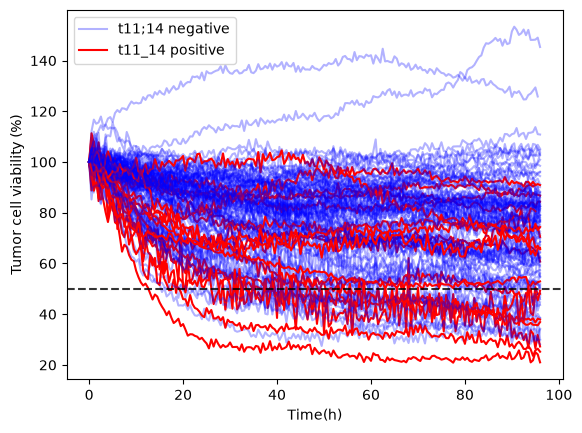

In [237]:
# first lets plot the trajectory of each patients viability

for key in highest_dose_dfs:
    df = highest_dose_dfs[key]
    label = 't11_14 positive' if obs_subset_df.loc[key]['t11_14'] == 1 else "t11;14 negative"
    col = "red" if obs_subset_df.loc[key]['t11_14'] == 1 else "blue"
    alpha = 1 if obs_subset_df.loc[key]['t11_14'] == 1 else 0.3

    sns.lineplot(df, c=col, alpha=alpha, label=label)
    plt.ylabel("Tumor cell viability (%)")
    
    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())

plt.axhline(50, ls='--', c='k', alpha=0.8) 


In [238]:
# calc AUC - highest dose
calculated_auc = {}
for key in highest_dose_dfs:
    df = highest_dose_dfs[key]
    x = df.index.astype(float).values
    y = df.values

    calculated_auc[key] = np.trapezoid(y=y, x=x)
calculated_auc = pd.Series(calculated_auc)

In [252]:
# calc AUC - all doses 

all_dose_auc = {}
for key in all_doses_dfs:
    df = all_doses_dfs[key]
    x = df.index.astype(float).values
    y = df.values

    all_dose_auc[key] = np.trapezoid(y=y, x=x)
all_dose_auc = pd.Series(all_dose_auc)

In [240]:
calculated_auc.max()

np.float64(12672.1968155)

<Axes: ylabel='Count'>

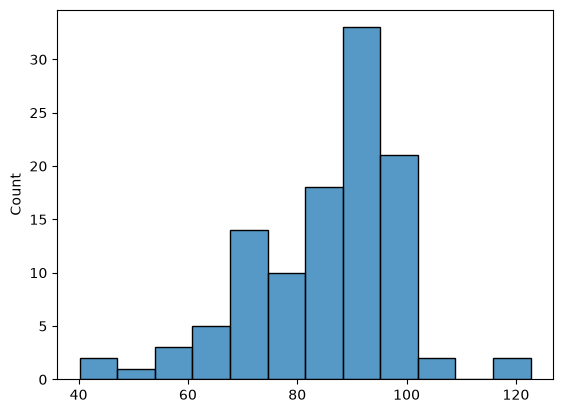

In [289]:
sns.histplot(vucs_log_dose_df)

<Axes: ylabel='Count'>

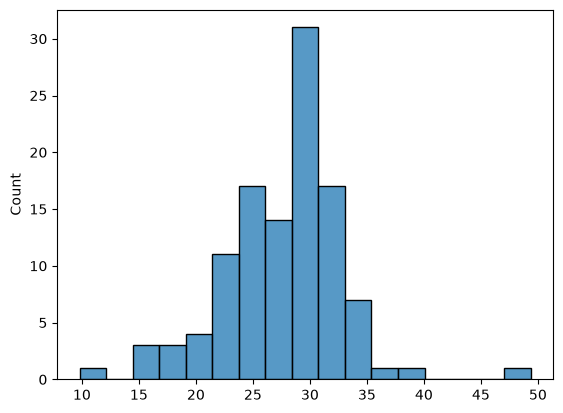

In [282]:
sns.histplot(vucs_df)

<Axes: ylabel='Count'>

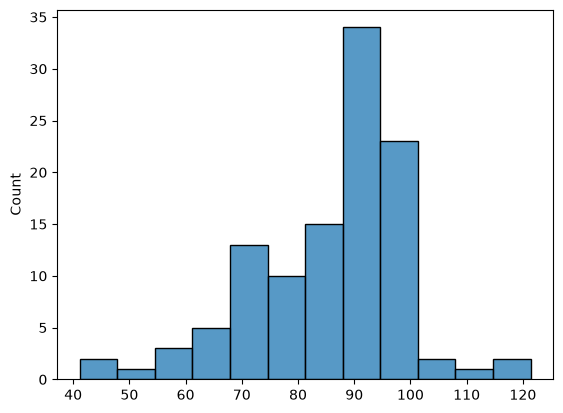

In [261]:
sns.histplot(all_dose_auc / 96) # This is the closest to the papers calculation so far

Text(0.5, 0, 'Calculated AUC (highest dose)')

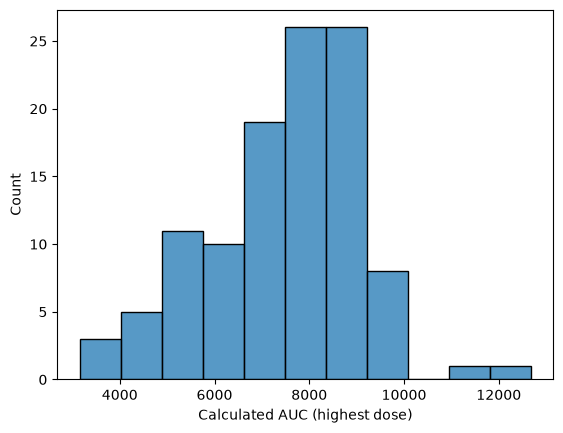

In [246]:
sns.histplot(calculated_auc)
plt.xlabel('Calculated AUC (highest dose)')

<Axes: xlabel='ABT-199', ylabel='Count'>

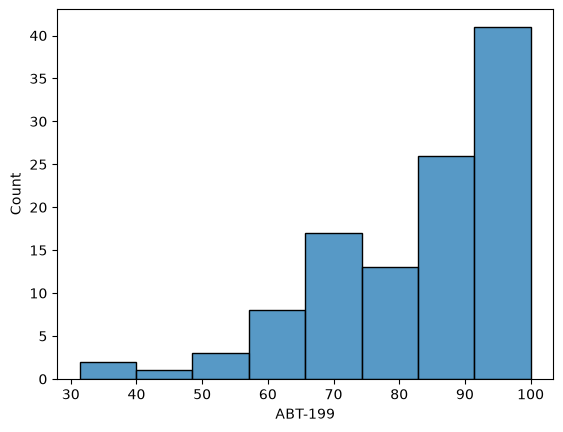

In [248]:
sns.histplot(mf_ad.obs['ABT-199'])